In [4]:
import sys
sys.path.append("../src")
import cv2, numpy as np, skimage
import matplotlib.pyplot as plt
import pandas as pd
from utils_cv import baca, tampil, statistik, kontras_bercak


# Langkah 5.1 Lengkapi modul praproses

In [5]:
%%writefile ../src/praproses.py
"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""
import json
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640,                     # sampling: lebar citra kerja (piksel)
    "gamma": 1.0,                     # < 1 mencerahkan, > 1 menggelapkan
    "clahe_clip": 2.0,                # 0 berarti CLAHE tidak dipakai
    "clahe_tile": 8,
    "penapis": "median",              # "none", "rerata", "gaussian", "median"
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,                   # 0 berarti tanpa penajaman
}


def praproses(img_bgr, p=None):
    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""
    p = {**PARAM_BAWAAN, **(p or {})}
    # TODO 1: ubah ukuran agar lebar = p["lebar"], rasio aspek tetap
    h, w = img_bgr.shape[:2]
    skala = p["lebar"] / w
    img = cv2.resize(img_bgr, (p["lebar"], round(h * skala)),
                     interpolation=cv2.INTER_AREA)
    # TODO 2: koreksi gamma bila gamma != 1
    if p["gamma"] != 1:
        lut = np.array([255 * (i / 255) ** p["gamma"]
                        for i in range(256)]).clip(0, 255).astype(np.uint8)
        img = cv2.LUT(img, lut)
    # TODO 3: CLAHE pada kanal V saja bila clahe_clip > 0
    if p["clahe_clip"] > 0:
        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"],
                                tileGridSize=(p["clahe_tile"], p["clahe_tile"]))
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
    # TODO 4: redam derau sesuai pilihan penapis
    if p["penapis"] == "median":
        img = cv2.medianBlur(img, p["kernel"])
    elif p["penapis"] == "rerata":
        img = cv2.blur(img, (p["kernel"], p["kernel"]))
    elif p["penapis"] == "gaussian":
        img = cv2.GaussianBlur(img, (p["kernel"], p["kernel"]), p["sigma"])
    # TODO 5: unsharp masking bila tajam_k > 0
    if p["tajam_k"] > 0:
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)
        img = cv2.addWeighted(img, 1 + p["tajam_k"], blur, -p["tajam_k"], 0)
    return img


def simpan_param(p, path="../hasil/param_praproses.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)


Overwriting ../src/praproses.py


# Kode 5.2 Evaluasi rangkaian praproses

In [6]:
from praproses import praproses, simpan_param

param = {"gamma": 1.0, "clahe_clip": 2.0, "clahe_tile": 4, "penapis": "median", "kernel": 3}
simpan_param(param, "../hasil/param_praproses.json")
KANAL = 2                    # ganti sesuai kanal terbaik Anda di Bagian 2
                             # (indeks BGR: 0 = B, 1 = G, 2 = R)
label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    out = praproses(img, param)
    baris.append([d.kondisi_cahaya,
                  kontras_bercak(img[:, :, KANAL], md, mb),
                  kontras_bercak(out[:, :, KANAL], md, mb)])
evaluasi = pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"])
print(evaluasi.groupby("kondisi").mean().round(2))


                KB_sebelum  KB_sesudah
kondisi                               
bayangan              4.65        7.59
gelap                 9.56       16.20
kontras_rendah        3.62        5.20
normal                8.51       10.39
terang                6.65        6.33


# Langkah 5.3 Uji bercak palsu pada kelas sehat

In [7]:
baris53 = []
for _, d in label[label.kelas == "sehat"].iterrows():
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    out = praproses(img, param)
    daun = md > 0
    baris53.append([d.kondisi_cahaya,
                    img[:, :, KANAL][daun].std(),
                    out[:, :, KANAL][daun].std()])
uji_sehat = pd.DataFrame(baris53, columns=["kondisi", "std_sebelum", "std_sesudah"])
print(uji_sehat.groupby("kondisi").mean().round(2))


                std_sebelum  std_sesudah
kondisi                                 
bayangan              14.13         9.54
gelap                  9.36         5.99
kontras_rendah        11.65         9.71
normal                11.36         8.86
terang                12.61        11.48


# Panel citra sehat sebelum dan sesudah

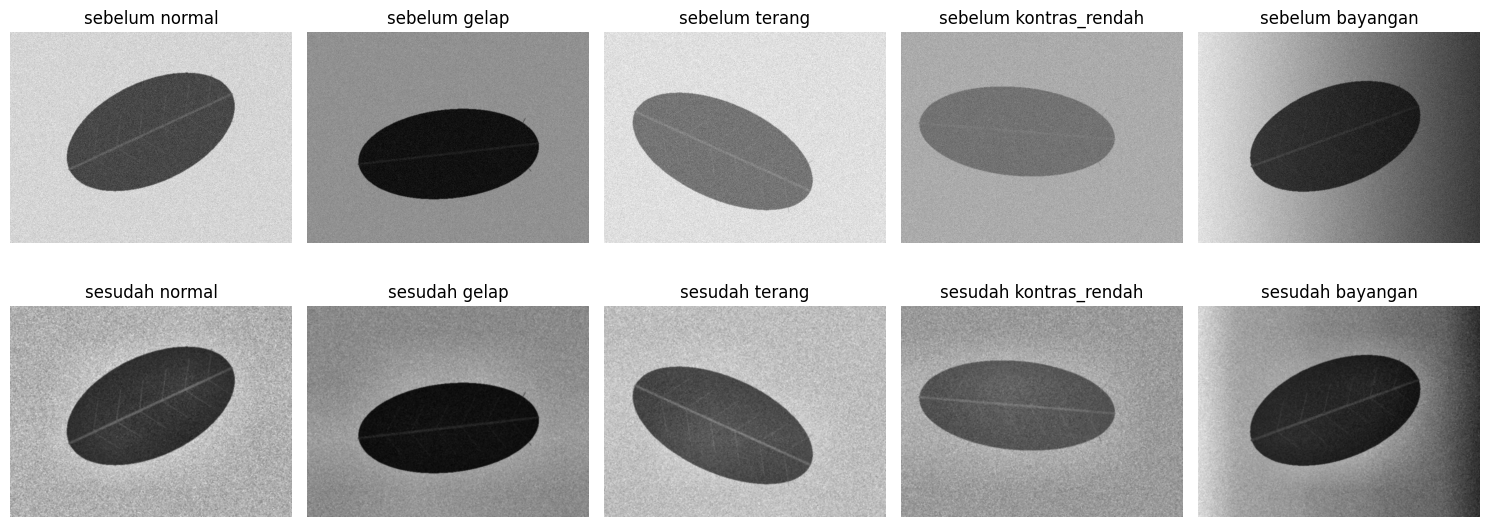

In [8]:
contoh = ["teh_001.png", "teh_002.png", "teh_003.png", "teh_004.png", "teh_005.png"]
judul = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for j, (nama, ket) in enumerate(zip(contoh, judul)):
    img = baca(f"../data/sintetis/citra/{nama}")
    out = praproses(img, param)
    axes[0, j].imshow(img[:, :, KANAL], cmap="gray", vmin=0, vmax=255)
    axes[0, j].set_title(f"sebelum {ket}"); axes[0, j].axis("off")
    axes[1, j].imshow(out[:, :, KANAL], cmap="gray", vmin=0, vmax=255)
    axes[1, j].set_title(f"sesudah {ket}"); axes[1, j].axis("off")
plt.tight_layout()
plt.savefig("../hasil/b5_panel_sehat.png", dpi=100, bbox_inches="tight")
plt.show()
